<a href="https://colab.research.google.com/github/rigorrp123-cloud/InteligenciaArtificial_y_RedesNeuronales_UANL_FIME/blob/main/AF5_Procesamiento_de_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
%matplotlib inline
print("Versiones:", "pandas", pd.__version__, "NumPy", np.__version__)

Versiones: pandas 2.2.3 NumPy 2.1.3


In [ ]:
URL = 'https://raw.githubusercontent.com/dilp90/InteligenciaArtificial_y_RedesNeuronales_UANL_FIME/main/MachineLearning/Datasets/robot_sensors.csv'
archivo = Path("robot_sensors.csv")
df = pd.read_csv(archivo if archivo.exists() else URL)
print("Dimensiones:", df.shape)
display(df.head())
df.info()
display(df.describe())

Dimensiones: (1000, 4)


,Tiempo (s),Distancia (cm),Velocidad (cm/s),Temperatura (°C)
0,0,43.708611,9.256646,23.925585
1,1,95.564288,27.095047,23.704682
2,2,75.879455,43.647292,33.593819
3,3,63.879264,36.611244,23.743193
4,4,24.041678,40.328057,24.079246


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Tiempo (s)        1000 non-null   int64  
 1   Distancia (cm)    970 non-null    float64
 2   Velocidad (cm/s)  970 non-null    float64
 3   Temperatura (°C)  970 non-null    float64
dtypes: float64(3), int64(1)
memory usage: 31.4 KB


,Tiempo (s),Distancia (cm),Velocidad (cm/s),Temperatura (°C)
count,1000.000000,970.000000,970.000000,970.000000
mean,499.500000,54.011809,25.203708,27.518110
std,288.819436,26.408040,14.632979,4.386129
min,0.000000,10.416882,0.160913,20.000175
25%,249.750000,30.581348,11.877176,23.890799
50%,499.500000,54.633590,25.874517,27.507535
75%,749.250000,76.891589,37.989158,31.409083
max,999.000000,99.974591,49.970686,34.967313


In [ ]:
display(df.isna().sum().rename("Nulos por columna").to_frame())
sin_nulos = df.dropna().copy()
velocidad_negativa = sin_nulos["Velocidad (cm/s)"] < 0
descartados = sin_nulos.loc[velocidad_negativa]
limpios = sin_nulos.loc[~velocidad_negativa].copy()
limpios = limpios.sort_values("Tiempo (s)").reset_index(drop=True)
resumen = pd.DataFrame({"Etapa": ["Original", "Filas con nulos eliminadas", "Velocidades negativas eliminadas", "Final"],
                        "Filas": [len(df), len(df)-len(sin_nulos), int(velocidad_negativa.sum()), len(limpios)]})
display(resumen)
print(f"Se conservó el {100*len(limpios)/len(df):.1f}% del dataset.")
display(descartados)
assert not limpios.isna().any().any()
assert (limpios["Velocidad (cm/s)"] >= 0).all()


,Nulos por columna
Tiempo (s),0
Distancia (cm),30
Velocidad (cm/s),30
Temperatura (°C),30


,Etapa,Filas
0,Original,1000
1,Filas con nulos eliminadas,87
2,Velocidades negativas eliminadas,0
3,Final,913


Se conservó el 91.3% del dataset.


,Tiempo (s),Distancia (cm),Velocidad (cm/s),Temperatura (°C)


In [ ]:
columnas = limpios.select_dtypes(include=np.number).columns
if limpios.empty:
    raise ValueError("No quedaron registros para normalizar.")
minimos = limpios[columnas].min()
maximos = limpios[columnas].max()
rangos = maximos - minimos
normalizados = limpios.copy()
normalizados[columnas] = (limpios[columnas] - minimos) / rangos.replace(0, 1)
parametros = pd.DataFrame({"Mínimo original": minimos, "Máximo original": maximos,
                           "Mínimo normalizado": normalizados[columnas].min(),
                           "Máximo normalizado": normalizados[columnas].max()})
display(parametros.round(6))
display(normalizados.head())
valores = normalizados[columnas].to_numpy()
assert np.isfinite(valores).all()
assert np.all((valores >= -1e-12) & (valores <= 1 + 1e-12))
print("Verificación correcta: datos finitos dentro de [0, 1].")


,Mínimo original,Máximo original,Mínimo normalizado,Máximo normalizado
Tiempo (s),0.000000,999.000000,0.0,1.0
Distancia (cm),10.416882,99.974591,0.0,1.0
Velocidad (cm/s),0.160913,49.970686,0.0,1.0
Temperatura (°C),20.000175,34.967313,0.0,1.0


,Tiempo (s),Distancia (cm),Velocidad (cm/s),Temperatura (°C)
0,0.000000,0.371735,0.182609,0.262269
1,0.001001,0.950755,0.540740,0.247509
2,0.002002,0.730954,0.873049,0.908233
3,0.003003,0.596960,0.731791,0.250082
4,0.004004,0.152134,0.806411,0.272535


Verificación correcta: datos finitos dentro de [0, 1].


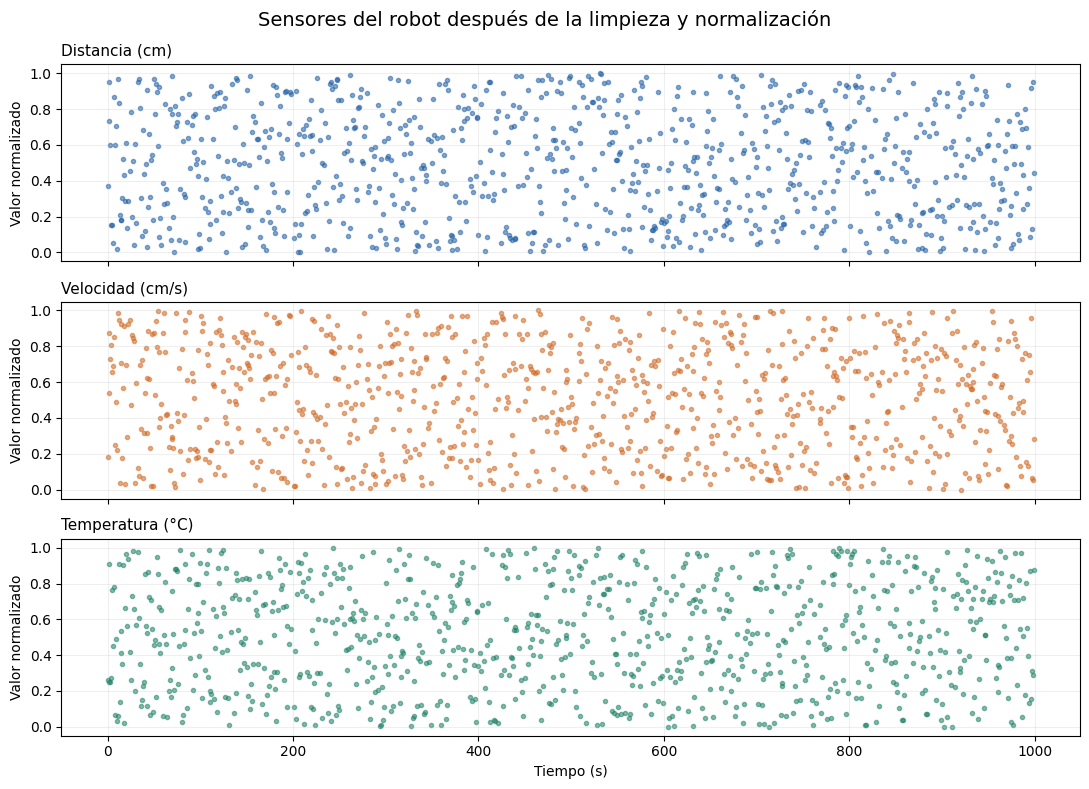

In [ ]:
sensores = ["Distancia (cm)", "Velocidad (cm/s)", "Temperatura (°C)"]
colores = ["#2563a6", "#d16b26", "#22836a"]
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, sharey=True)
for ax, sensor, color in zip(axes, sensores, colores):
    ax.scatter(limpios["Tiempo (s)"], normalizados[sensor], s=9, alpha=0.55, color=color)
    ax.set_title(sensor, loc="left", fontsize=11)
    ax.set_ylabel("Valor normalizado")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Tiempo (s)")
fig.suptitle("Sensores del robot después de la limpieza y normalización", fontsize=14)
fig.tight_layout()
fig.savefig("sensores_normalizados.png", dpi=160, bbox_inches="tight")
plt.show()
